# Imports and preprocess data

In [30]:
import numpy as np 
from pathlib import Path
import sys, os, json
import matplotlib.pyplot as plt
sys.path.append(os.path.join(os.getcwd(), '..'))

from utils.eda_helpers import clean_data
from utils.eda_helpers import read_csv_numeric

import importlib
import utils.decision_tree, utils.random_forest, utils.cv, utils.sampling_methods
importlib.reload(utils.decision_tree)
importlib.reload(utils.random_forest)
importlib.reload(utils.cv)
importlib.reload(utils.sampling_methods)
from utils.decision_tree import Decision_Tree
from utils.random_forest import Random_Forest
from utils.cv import compute_roc_auc, compute_training_error, cross_validate
from utils.sampling_methods import undersample, oversample

In [2]:
file_path = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA_FOLDER = os.path.join(file_path, '..', 'dataset')
x_indices, x_data = read_csv_numeric(os.path.join(DATA_FOLDER, "x_train.csv"))
y_indices, y_data = read_csv_numeric(os.path.join(DATA_FOLDER, "y_train.csv"))

In [3]:
del x_indices["Id"]
del y_indices["Id"]
x_data = clean_data(x_data, x_indices)

In [4]:
columns_to_train_extended = [
    "VETERAN3", "STOPSMK2", "BLIND", "WTKG3", "CHCCOPD1", "EDUCA", "_SMOKER3", 
    "CHKHEMO3", "METVL11_", "_LMTSCL1", "SEX", "_RFSEAT2", "_ASTHMS1", "_PASTRNG",
      "TOLDHI2", "CVDSTRK3", "LMTJOIN3", "_DRNKWEK", "FLUSHOT6", "_FRUITEX",
        "PA1VIGM_", "CHILDREN", "BEANDAY_", "EXERANY2", "AVEDRNK2", "_BMI5", 
        "MAXVO2_", "MARITAL", "PAMIN21_", "_VEGETEX", "CHOLCHK", "HIVTST6", 
        "_AGE80", "USEEQUIP", "DROCDY3_", "FEETCHK", "ORNGDAY_", "PAMIN11_", 
        "_MINAC21", "PAFREQ2_", "_CASTHM1", "METVL21_", "DRADVISE", "BPMEDS", 
        "_FRUTSUM", "MEDCOST", "VEGEDA1_", "PREDIAB1", "GENHLTH", "PERSDOC2", 
        "_RFHLTH", "CHCOCNCR", "_RACE_G1", "DIFFALON", "_CRACE1", "FLSHTMY2", 
        "PADUR2_", "EMPLOY1", "INCOME2", "USENOW3", "_PASTAE1", "PAFREQ1_", 
        "WTCHSALT", "DRNKANY5", "CHCSCNCR", "SXORIENT", "GRENDAY_", "MENTHLTH", 
        "MAXDRNKS", "CHCKIDNY", "PAVIG11_", "DRNK3GE5", "_TOTINDA", "MSCODE", 
        "ADDEPEV2", "QLACTLM2", "PNEUVAC3", "SMOKDAY2", "_AIDTST3", "_PAREC1", 
        "EXRACT21", "_LMTWRK1", "_LMTACT1", "STRFREQ_", "DIFFDRES", "_MRACE1", 
        "TRNSGNDR", "DIABETE3", "INSULIN", "DECIDE", "FEETCHK2", "HAVARTH3", 
        "DIABAGE2", "DOCTDIAB", "PA1MIN_", "_MINAC11", "EXRACT11", "_PACAT1", 
        "LONGWTCH", "_MISVEGN", "CHECKUP1", "DIFFWALK", "PHYSHLTH", "FRUTDA1_", 
        "FRUIT1", "SMOKE100", "PAVIG21_", "ARTHSOCL", "_PAINDX1", "PAMISS1_", 
        "BLOODCHO", "HTM4", "ALCDAY5", "RENTHOM1", "_MISFRTN", "SCNTWRK1", 
        "POORHLTH", "PADUR1_", "FC60_", "_VEGESUM", "BPHIGH4"]


# this is the one we should use for training
final_feature_set = ['_CASTHM1', 'FLUSHOT6', 'METVL11_', '_PASTRNG', 'EDUCA', 'CHCCOPD1', 'DRADVISE', 
                     'CHCKIDNY', 'ARTHSOCL', 'MENTHLTH', 'SMOKE100', 'DOCTDIAB', 'DIABAGE2', 'VETERAN3', 
                     'CHKHEMO3', 'SEX', '_DRNKWEK', 'JOINPAIN', 'MARITAL', 'EXERANY2', '_PACAT1', 'INSULIN', 
                     'DIFFALON', 'FRUIT1', 'QLACTLM2', 'BLIND', 'PADUR2_', 'PAFREQ2_', 'LMTJOIN3', 'CHOLCHK', 
                     'POORHLTH', 'DIABETE3', '_FRUTSUM', 'PERSDOC2', 'EXRACT21', 'FEETCHK', '_VEGESUM', 'PNEUVAC3', 
                     'BPHIGH4', 'GENHLTH', 'EXRACT11', '_BMI5', 'DECIDE', '_ASTHMS1', '_MRACE1', '_LMTSCL1', 'ORNGDAY_', 
                     'MSCODE', 'PHYSHLTH', 'TOLDHI2', 'PADUR1_', 'DIFFWALK', 'BEANDAY_', 'CHCSCNCR', 'PAFREQ1_', '_AIDTST3', 
                     'FLSHTMY2', 'PA1VIGM_', 'METVL21_', 'SXORIENT', 'ARTHDIS2', 'PA1MIN_', 'MAXVO2_', '_RACE_G1', 'LONGWTCH', 
                     'SCNTWRK1', 'FEETCHK2', 'EMPLOY1', 'BLOODCHO', 'USENOW3', 'DRNKANY5', '_PAREC1', 'DIFFDRES', 'USEEQUIP', 
                     'ADDEPEV2', '_AGE80', 'HTM4', 'INCOME2', 'CVDSTRK3', 'CHCOCNCR', 'MEDCOST', 'PREDIAB1', 'BPMEDS', 'HAVARTH3', 
                     'CHECKUP1', 'TRNSGNDR', 'CHILDREN']


In [5]:
len(final_feature_set)

87

In [6]:
x_train = x_data.copy()
col_means = np.nanmean(x_train, axis=0)
inds = np.where(np.isnan(x_train))
x_train[inds] = np.round(np.take(col_means, inds[1])).astype(int)
x_train

array([[0.00000e+00, 5.30000e+01, 1.10000e+01, ..., 1.00000e+00,
        1.00000e+00, 2.00000e+00],
       [1.00000e+00, 3.30000e+01, 1.20000e+01, ..., 1.00000e+00,
        1.00000e+00, 2.00000e+00],
       [2.00000e+00, 2.00000e+01, 1.00000e+01, ..., 1.00000e+00,
        2.00000e+00, 2.00000e+00],
       ...,
       [3.28132e+05, 3.90000e+01, 1.00000e+01, ..., 2.00000e+00,
        2.00000e+00, 2.00000e+00],
       [3.28133e+05, 3.30000e+01, 1.20000e+01, ..., 1.00000e+00,
        1.00000e+00, 2.00000e+00],
       [3.28134e+05, 3.20000e+01, 9.00000e+00, ..., 1.00000e+00,
        1.00000e+00, 2.00000e+00]])

In [7]:
y_data[y_data[:, -1] == -1, -1] = 0
y_data[:, -1].sum()

28975.0

# Train DT

Undersampling done.



[Progress] Split calls: 5
[Progress] Split calls: 10
[Progress] Split calls: 15
[Progress] Split calls: 20
[Progress] Split calls: 25
[Progress] Split calls: 30
[Progress] Split calls: 35
[Progress] Split calls: 40
[Progress] Split calls: 45
[Progress] Split calls: 50
[Progress] Split calls: 55
[Progress] Split calls: 60


Train accuracy: 0.7539948231233822


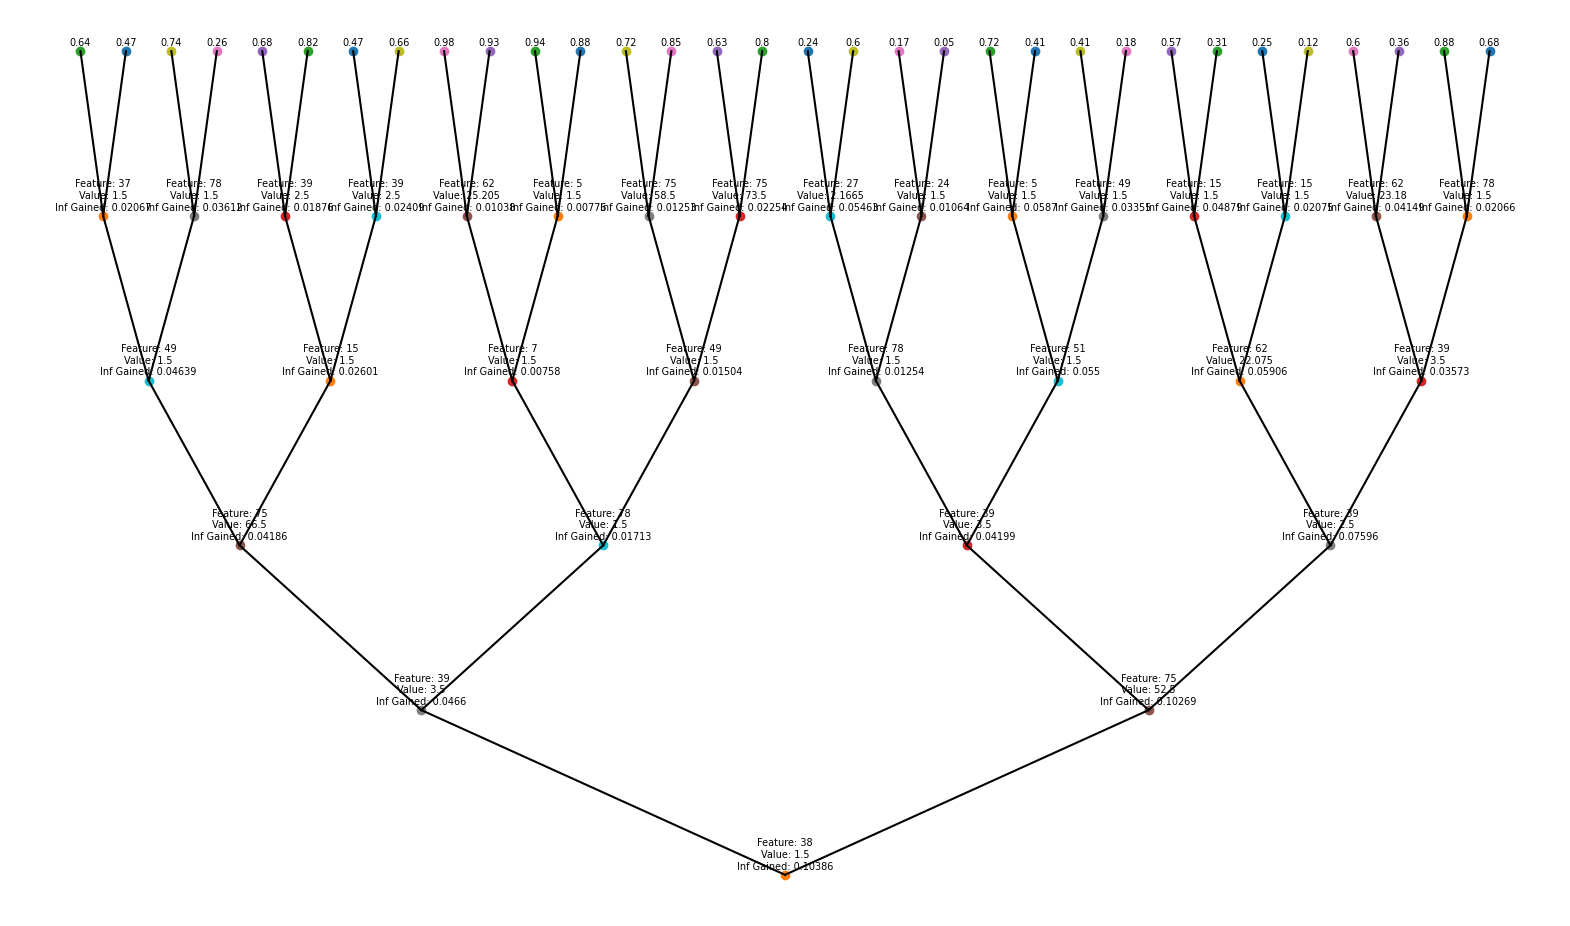

In [8]:
selected_indices = [x_indices[col] for col in final_feature_set if col in x_indices]
x_selected = x_train[:, selected_indices]

# undersample
X_bal, y_bal = undersample(x_selected, y_data[:, 1], ratio=1.0, seed=42)
print(f"Undersampling done.\n")

dt = Decision_Tree(
    maximum_depth=6,
    minimum_leaves=3,
    splitting_criterion="entropy",
    stopping_criterion=0.0,
    show_split_progress=True
)
dt.train(X_bal, y_bal.ravel())

preds = dt.predict(X_bal)
print("Train accuracy:", np.mean(preds == y_bal.ravel()))
dt.print_tree()

In [9]:
# --- Check prediction distribution ---
unique, counts = np.unique(preds, return_counts=True)
print("Prediction counts:", dict(zip(unique, counts)))

# --- Compare to true label distribution ---
unique_true, counts_true = np.unique(y_bal, return_counts=True)
print("True label counts:", dict(zip(unique_true, counts_true)))


Prediction counts: {0.0: 26927, 1.0: 31023}
True label counts: {0.0: 28975, 1.0: 28975}


In [10]:
y_true = y_bal.ravel().astype(int)
y_pred = preds.astype(int)
y_proba = dt.predict_proba(X_bal)

In [11]:
# --- Compute metrics manually ---
tp = np.sum((y_pred == 1) & (y_true == 1))
tn = np.sum((y_pred == 0) & (y_true == 0))
fp = np.sum((y_pred == 1) & (y_true == 0))
fn = np.sum((y_pred == 0) & (y_true == 1))

In [12]:
accuracy  = (tp + tn) / (tp + tn + fp + fn + 1e-10)
precision = tp / (tp + fp + 1e-10)
recall    = tp / (tp + fn + 1e-10)
f1        = 2 * precision * recall / (precision + recall + 1e-10)
roc_auc   = compute_roc_auc(y_true, y_proba)

In [13]:

# Print metrics
print("\n=== Decision Tree Evaluation Metrics ===")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC AUC  : {roc_auc:.4f}")


=== Decision Tree Evaluation Metrics ===
Accuracy : 0.7540
Precision: 0.7372
Recall   : 0.7893
F1 Score : 0.7624
ROC AUC  : 0.1805


In [14]:
# --- Confusion matrix -----
conf_matrix = np.array([[tn, fp],
                        [fn, tp]])

print("\nConfusion Matrix:")
print(conf_matrix)


Confusion Matrix:
[[20823  8152]
 [ 6104 22871]]


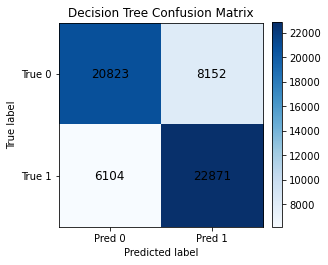

In [15]:
# --- Plot confusion matrix ---
fig, ax = plt.subplots(figsize=(4, 4))
im = ax.imshow(conf_matrix, cmap="Blues")

# Tick labels
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Pred 0", "Pred 1"])
ax.set_yticklabels(["True 0", "True 1"])

# Annotate cells
for i in range(2):
    for j in range(2):
        ax.text(j, i, conf_matrix[i, j], ha="center", va="center", color="black", fontsize=12)

ax.set_title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.show()

# Cross Validation DT

## Helper functions
We define some helper functions that will be used in our general cross_validate function.

In [16]:
# --- Train a Decision Tree and return the model ---
def train_decision_tree(y_train, X_train, **model_kwargs):
    dt = Decision_Tree(**model_kwargs)
    dt.train(X_train, y_train.ravel())
    return dt


# --- Predict labels and probabilities from a trained model ---
def predict_dt(X_val, model):
    y_pred = model.predict(X_val).astype(int)
    y_proba = model.predict_proba(X_val)
    return y_pred, y_proba


# --- Compute metrics (same structure as logistic version) ---
def compute_dt_metrics(y_true, X_val, model, returning="all", threshold=0.5):
    y_true = y_true.ravel().astype(int)
    y_pred, y_proba = predict_dt(X_val, model)

    tp = np.sum((y_pred == 1) & (y_true == 1))
    tn = np.sum((y_pred == 0) & (y_true == 0))
    fp = np.sum((y_pred == 1) & (y_true == 0))
    fn = np.sum((y_pred == 0) & (y_true == 1))

    accuracy  = (tp + tn) / (tp + tn + fp + fn + 1e-10)
    error     = 1 - accuracy
    precision = tp / (tp + fp + 1e-10)
    recall    = tp / (tp + fn + 1e-10)
    f1        = 2 * precision * recall / (precision + recall + 1e-10)
    roc_auc   = compute_roc_auc(y_true, y_proba)

    metrics = {
        "error": error,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc,
    }

    if returning == "all":
        return metrics
    else:
        return metrics[returning]


In [17]:
# --- Select relevant features ---
selected_indices = [x_indices[col] for col in final_feature_set if col in x_indices]
x_selected = x_train[:, selected_indices]

## Grid Search
We perform a grid search over some hyperparameter options for the DT in order to find the best combination of hyperparameters for our data.

In [31]:
# hyperparameter choices for the grid
depth_values = [6, 10, 15, 20]
min_leaves_values = [1, 5, 10, 20, 40]
ratios = [1, 1.5, 2, 2.5, 3]
criteria = ["gini"] # exclude entropy for now, we can compare gini vs entropy for the best set hyperparameters

# total combinations
total_combinations = len(depth_values) * len(min_leaves_values) * len(ratios) * len(criteria)
print(f"Total combinations to evaluate: {total_combinations}")

results_grid_search_dt = []

Total combinations to evaluate: 100


In [33]:
# counter for progress


combination_id = 0

# grid search loop
for depth in depth_values:
    for min_leaves in min_leaves_values:
        for ratio in ratios:
            for criterion in criteria:
                combination_id += 1
                print(f"\n({combination_id}/{total_combinations}) --- "
                      f"Depth={depth} | Leaves={min_leaves} | Ratio={ratio} | Crit={criterion} ---")

                res = cross_validate(
                    model_fn=train_decision_tree,
                    X=x_selected,
                    y=y_data[:, 1],
                    k_folds=5,
                    seed=42,
                    sampling_fn=oversample,
                    sampling_kwargs={"ratio": ratio, "seed": 42},
                    model_kwargs={
                        "maximum_depth": depth,
                        "minimum_leaves": min_leaves,
                        "splitting_criterion": criterion,
                        "stopping_criterion": 0.0,
                        "splits_by_feature": 8,
                        "show_split_progress": False
                    },
                    predict_fn=predict_dt,
                    metric_fn=compute_dt_metrics,
                    verbose=True
                )
                
                entry = {
                    "model_name": "Decision_Tree",
                    "sampling_method": "oversample",
                    "sampling_kwargs": {"ratio": ratio, "seed": 42},
                    "model_hyperparams": {
                        "maximum_depth": depth,
                        "minimum_leaves": min_leaves,
                        "splitting_criterion": criterion,
                        "stopping_criterion": 0.0,
                        "splits_by_feature": 8,
                        "show_split_progress": False
                    },
                    "metrics": res
                }
                results_grid_search_dt.append(entry)
                print("F1:", res["f1"], "Accuracy:", res["accuracy"])



(1/100) --- Depth=6 | Leaves=1 | Ratio=1 | Crit=gini ---
Fold 1/5 → error:0.257, accuracy:0.743, precision:0.222, recall:0.771, f1:0.344, roc_auc:0.193
Fold 2/5 → error:0.277, accuracy:0.723, precision:0.213, recall:0.789, f1:0.335, roc_auc:0.196
Fold 3/5 → error:0.278, accuracy:0.722, precision:0.216, recall:0.809, f1:0.341, roc_auc:0.188
Fold 4/5 → error:0.265, accuracy:0.735, precision:0.218, recall:0.779, f1:0.341, roc_auc:0.187
Fold 5/5 → error:0.326, accuracy:0.674, precision:0.195, recall:0.851, f1:0.317, roc_auc:0.192
F1: 0.33564647681002435 Accuracy: 0.7195361665168287

(2/100) --- Depth=6 | Leaves=1 | Ratio=1.5 | Crit=gini ---
Fold 1/5 → error:0.215, accuracy:0.785, precision:0.245, recall:0.701, f1:0.363, roc_auc:0.186
Fold 2/5 → error:0.242, accuracy:0.758, precision:0.230, recall:0.738, f1:0.351, roc_auc:0.184
Fold 3/5 → error:0.238, accuracy:0.762, precision:0.234, recall:0.742, f1:0.356, roc_auc:0.177
Fold 4/5 → error:0.260, accuracy:0.740, precision:0.220, recall:0.768

In [ ]:
output_dir = os.path.join(os.getcwd(), '..', 'results', 'eval')
os.makedirs(output_dir, exist_ok=True)

output_path_dt = os.path.join(output_dir, 'results_grid_search_dt_oversample.json')
with open(output_path_dt, "w", encoding="utf-8") as f:
    json.dump(results_grid_search_dt, f, indent=4, ensure_ascii=False)

print(f"\nGrid search results for Decision Tree saved to:\n{output_path_dt}")


Grid search results for Decision Tree saved to:
c:\Users\clued\OneDrive - epfl.ch\FirstSemester\MachineLearning\Project\cs433_medical_ml\notebooks\..\results\eval\results_grid_search_dt.json


In [23]:
best_result = max(results_grid_search_dt, key=lambda x: x["metrics"]["f1"])
print("\n=== Best Decision Tree Configuration ===")


print(f"Depth: {best_result['model_hyperparams']['maximum_depth']}, "
      f"Min leaves: {best_result['model_hyperparams']['minimum_leaves']}, "
      f"Ratio: {best_result['sampling_kwargs']['ratio']}, "
      f"Criterion: {best_result['model_hyperparams']['splitting_criterion']}")
print(f"F1: {best_result['metrics']['f1']:.4f}, Recall: {best_result['metrics']['recall']:.4f}, "
      f"Precision: {best_result['metrics']['precision']:.4f}")



=== Best Decision Tree Configuration ===
Depth: 10, Min leaves: 40, Ratio: 2.5, Criterion: gini
F1: 0.4002, Recall: 0.5584, Precision: 0.3120


# Train DT on train set, using best hyperparameters
We use the hyperparameters found through grid search to train a DT model and make predictions on the test set, that will be used for submission.

In [24]:
from utils.helpers import load_csv_data, create_csv_submission

In [25]:
# load test data
DATA_FOLDER = os.path.join(file_path, '..', 'dataset')
x_indices_test, x_test = read_csv_numeric(os.path.join(DATA_FOLDER, "x_test.csv"))

# extract test IDs before cleaning 
test_ids = x_test[:, x_indices_test["Id"]].astype(int)

# clean it
if "Id" in x_indices_test:
    del x_indices_test["Id"]
x_test = clean_data(x_test, x_indices_test)

In [26]:
# Keep only same features as in training 
x_test_selected = x_test[:, [x_indices_test[col] for col in final_feature_set if col in x_indices_test]]

# Compute column means from training data 
col_mean = np.nanmean(x_selected, axis=0)

# Impute missing values using training means 
inds_test = np.where(np.isnan(x_test_selected))
x_test_selected[inds_test] = np.take(col_mean, inds_test[1])

print("Training feature shape:", x_selected.shape)
print("Test feature shape:", x_test_selected.shape)
print("Imputation completed.")

Training feature shape: (328135, 87)
Test feature shape: (109379, 87)
Imputation completed.


In [27]:
best_params = best_result["model_hyperparams"]
best_sampling = best_result["sampling_kwargs"]

# Rebalance full training data with best ratio
X_bal, y_bal = undersample(x_selected, y_data[:, 1], **best_sampling)

# Train final model
dt_final = Decision_Tree(**best_params)
dt_final.train(X_bal, y_bal.ravel())

In [28]:
# Predict on true test set
y_pred_test = dt_final.predict(x_test_selected)

# Convert 0 → -1 if needed for submission
y_pred_test = np.where(y_pred_test == 0, -1, 1)

create_csv_submission(test_ids, y_pred_test, "dt_best_submission.csv")
print("\nSubmission file 'dt_best_submission.csv' created successfully.")


Submission file 'dt_best_submission.csv' created successfully.


In [29]:
assert x_test_selected.shape[1] == x_selected.shape[1], "Feature mismatch between train and test!"
assert len(test_ids) == len(y_pred_test), "Prediction count mismatch!"